# Assignment 9 baseline classifier

This notebook trains a baseline classifier for the visitor's first statement. The target is the six-class label in `expand_other`. The Assignment 7 label stays in `final_label` and is not used for training.

The classes are:

- buyer
- seller
- renter
- media outreach
- realtor network
- other

The classifier is logistic regression on TF-IDF word unigrams. Each run trains on 20 messages and tests on the other 10. `N_REPEATS` controls how many times that split-and-train cycle runs. The default is 10. Every repeat draws a new random split, refits the vectorizer on that repeat's training rows only, and scores only the 10 held-out rows.

Run this notebook with a Python environment that has `pandas`, `numpy`, `scikit-learn`, and `matplotlib`.


## Settings

Change `TRAIN_SIZE`, `N_REPEATS`, or `RANDOM_SEED`, then run the notebook from the top. Repeat 1 uses `RANDOM_SEED`. Repeat 2 uses `RANDOM_SEED + 1`. Later repeats follow that same rule, so the first repeats stay fixed if you raise `N_REPEATS`.

`TRAIN_SIZE` is 20, so the test set is the other 10 messages. The split is a random sample without replacement. It is not stratified. Seller and realtor network each have one message, and a stratified splitter cannot place a one-row class on both sides of the split.


In [1]:
%matplotlib inline
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, roc_auc_score
from sklearn.pipeline import Pipeline

# How many messages are used to fit the vectorizer and the classifier.
TRAIN_SIZE = 20
# How many independent 20/10 splits to run. Set this to 10 for the baseline.
N_REPEATS = 10
# Repeat k uses RANDOM_SEED + k, with the first repeat numbered 0.
RANDOM_SEED = 42

LABEL_COLUMN = "expand_other"
CLASS_NAMES = [
    "buyer",
    "seller",
    "renter",
    "media outreach",
    "realtor network",
    "other",
]
METRIC_NAMES = ["precision", "recall", "f1", "specificity", "auc"]

DATA_CANDIDATES = [
    Path("labeled_visitor_intent.csv"),
    Path("Module_9_assignment/labeled_visitor_intent.csv"),
]


## Six-class dataset

Assignment 7 stored one label per message in `final_label` (`buyer`, `seller`, `renter`, `other`). `expand_other` keeps that decision for most messages and moves some `other` messages into `media outreach` or `realtor network`.

The training label is `expand_other`, normalized to the lowercase names above. `final_label` is left unchanged in the CSV. The next cell prints the messages whose six-class label differs from the Assignment 7 label, plus the class counts.


In [2]:
def find_data_path():
    for candidate in DATA_CANDIDATES:
        if candidate.exists():
            return candidate
    raise FileNotFoundError(
        "Could not find labeled_visitor_intent.csv. "
        "Run this notebook from Module_9_assignment or from the repository root."
    )


def normalize_label(raw_label):
    return " ".join(str(raw_label).strip().lower().split())


data_path = find_data_path()
dataset = pd.read_csv(data_path)
dataset["assignment_7_label"] = dataset["final_label"].map(normalize_label)
dataset["label"] = dataset[LABEL_COLUMN].map(normalize_label)

unknown_labels = sorted(set(dataset["label"]) - set(CLASS_NAMES))
if unknown_labels:
    raise ValueError("Unexpected labels in expand_other: " + ", ".join(unknown_labels))
if TRAIN_SIZE < 1 or TRAIN_SIZE >= len(dataset):
    raise ValueError("TRAIN_SIZE must leave at least one test message.")
if N_REPEATS < 1:
    raise ValueError("N_REPEATS must be at least 1.")

test_size = len(dataset) - TRAIN_SIZE
print(f"Loaded {len(dataset)} messages from {data_path}.")
print(f"Each repeat trains on {TRAIN_SIZE} and tests on {test_size}.")

class_counts = pd.DataFrame({
    "assignment_7_count": dataset["assignment_7_label"].value_counts(),
    "six_class_count": dataset["label"].value_counts(),
}).reindex(CLASS_NAMES).fillna(0).astype(int)
class_counts.index.name = "class_name"
display(class_counts)

changed_rows = dataset.loc[
    dataset["assignment_7_label"] != dataset["label"],
    ["item_id", "assignment_7_label", "expand_other", "visitor_statement"],
]
print("Messages whose six-class label differs from the Assignment 7 label:")
display(changed_rows)


Loaded 30 messages from labeled_visitor_intent.csv.
Each repeat trains on 20 and tests on 10.


,assignment_7_count,six_class_count
class_name,,
buyer,19,19
seller,1,1
renter,3,3
media outreach,0,2
realtor network,0,1
other,7,4


Messages whose six-class label differs from the Assignment 7 label:


,item_id,assignment_7_label,expand_other,visitor_statement
3,V4,other,Realtor Network,Are you from xxx xxx xxx(company)?
20,V21,other,Media Outreach,hi could I have an email for xxx xxxxxx(name) ...
26,V27,other,Media Outreach,How does the problem of blue green algae affec...


## Classifier and features

Each statement becomes a TF-IDF vector of word unigrams. The vectorizer lowercases text, keeps every word that appears at least once in that repeat's training rows, and does not delete stop words. Messages are short, so dropping common words would drop part of the request.

Logistic regression then predicts the six-class label from that vector.

- `C=1.0` is the usual L2 penalty.
- `class_weight="balanced"` gives the rare classes a larger share of the loss. Buyer is most of the file, so equal row weights would fit buyer and ignore the rest.
- `solver="lbfgs"` and `max_iter=1000` fit the multiclass model.
- The classifier `random_state` stays at `RANDOM_SEED` on every repeat. The split is the part that changes.

This is a reasonable baseline for 30 short messages. The model is small enough to refit once per split, and `predict_proba` supplies the scores that one-vs-rest AUC requires. A new pipeline is created for every repeat. The TF-IDF vocabulary is estimated from that repeat's 20 training statements only.


In [3]:
def make_pipeline():
    return Pipeline(
        steps=[
            (
                "tfidf",
                TfidfVectorizer(
                    lowercase=True,
                    ngram_range=(1, 1),
                    min_df=1,
                ),
            ),
            (
                "classifier",
                LogisticRegression(
                    C=1.0,
                    class_weight="balanced",
                    solver="lbfgs",
                    max_iter=1000,
                    random_state=RANDOM_SEED,
                ),
            ),
        ]
    )


def train_test_positions(row_count, train_size, split_seed):
    generator = np.random.RandomState(split_seed)
    positions = generator.permutation(row_count)
    train_positions = positions[:train_size]
    test_positions = positions[train_size:]
    return train_positions, test_positions


def class_probabilities(pipeline, statements, class_names):
    # Classes absent from the training rows have no coefficient. Their score stays 0.
    raw_probabilities = pipeline.predict_proba(statements)
    trained_names = list(pipeline.named_steps["classifier"].classes_)
    aligned = np.zeros((len(statements), len(class_names)), dtype=float)
    for column_index, class_name in enumerate(trained_names):
        aligned[:, class_names.index(class_name)] = raw_probabilities[:, column_index]
    return aligned


def safe_divide(numerator, denominator):
    if denominator == 0:
        return np.nan
    return numerator / denominator


def f1_from_precision_recall(precision, recall):
    if np.isnan(precision) or np.isnan(recall):
        return np.nan
    if precision + recall == 0:
        return 0.0
    return 2 * precision * recall / (precision + recall)


def one_vs_rest_counts(true_labels, predicted_labels, positive_name):
    true_positive = 0
    false_positive = 0
    true_negative = 0
    false_negative = 0
    for true_label, predicted_label in zip(true_labels, predicted_labels):
        actual_positive = true_label == positive_name
        predicted_positive = predicted_label == positive_name
        if actual_positive and predicted_positive:
            true_positive += 1
        elif actual_positive and not predicted_positive:
            false_negative += 1
        elif (not actual_positive) and predicted_positive:
            false_positive += 1
        else:
            true_negative += 1
    return true_positive, false_positive, true_negative, false_negative


def one_vs_rest_auc(true_labels, positive_scores, positive_name):
    binary_truth = np.asarray(
        [1 if label == positive_name else 0 for label in true_labels],
        dtype=int,
    )
    positive_count = int(binary_truth.sum())
    if positive_count == 0 or positive_count == len(binary_truth):
        return np.nan
    return float(roc_auc_score(binary_truth, positive_scores))


def macro_average(values):
    numeric_values = np.asarray(values, dtype=float)
    defined_values = numeric_values[~np.isnan(numeric_values)]
    if defined_values.size == 0:
        return np.nan
    return float(defined_values.mean())


def probability_column(class_name):
    return "probability_" + class_name.replace(" ", "_")


def join_names(names):
    if len(names) == 0:
        return "(none)"
    return ", ".join(names)


## Evaluation

For each class, that class is the positive class and the other five classes are the negative class.

- Precision is TP / (TP + FP). It is N/A when the model never predicts the class, because the denominator is 0.
- Recall is TP / (TP + FN). It is N/A when the test set has no message of that class.
- F1 is the harmonic mean of precision and recall when both are defined. If both are 0, F1 is 0. If either is N/A, F1 is N/A.
- Specificity is TN / (TN + FP). It is N/A when the test set has no negative example.
- AUC uses the predicted probability of the class, not the final label. It is N/A when the test set is missing either a positive or a negative example.

The macro score for a repeat is the unweighted mean of the classes whose metric is defined on that test set. A class with N/A is left out of that mean rather than filled in as 0. The per-class table still shows the N/A. The repeat table also shows how many classes entered each macro. Macro F1 usually counts fewer classes than macro recall, because F1 is N/A when the model never predicts the class.

The same 10 test messages are used for every metric in a repeat. Training rows are not scored.


In [4]:
def score_repeat(repeat_number, split_seed, statements, labels, item_ids, statement_text):
    train_positions, test_positions = train_test_positions(len(statements), TRAIN_SIZE, split_seed)
    pipeline = make_pipeline()
    pipeline.fit(statements[train_positions], labels[train_positions])

    actual_labels = labels[test_positions]
    predicted_labels = pipeline.predict(statements[test_positions])
    probabilities = class_probabilities(pipeline, statements[test_positions], CLASS_NAMES)
    trained_classes = set(pipeline.named_steps["classifier"].classes_)

    class_rows = []
    for class_index, class_name in enumerate(CLASS_NAMES):
        true_positive, false_positive, true_negative, false_negative = one_vs_rest_counts(
            actual_labels,
            predicted_labels,
            class_name,
        )
        precision = safe_divide(true_positive, true_positive + false_positive)
        recall = safe_divide(true_positive, true_positive + false_negative)
        class_rows.append({
            "repeat": repeat_number,
            "split_seed": split_seed,
            "class_name": class_name,
            "precision": precision,
            "recall": recall,
            "f1": f1_from_precision_recall(precision, recall),
            "specificity": safe_divide(true_negative, true_negative + false_positive),
            "auc": one_vs_rest_auc(actual_labels, probabilities[:, class_index], class_name),
            "test_support": int(np.sum(actual_labels == class_name)),
            "train_support": int(np.sum(labels[train_positions] == class_name)),
            "true_positive": true_positive,
            "false_positive": false_positive,
            "true_negative": true_negative,
            "false_negative": false_negative,
        })

    prediction_rows = []
    for row_index, position in enumerate(test_positions):
        prediction_row = {
            "repeat": repeat_number,
            "split_seed": split_seed,
            "item_id": item_ids[position],
            "visitor_statement": statement_text[position],
            "actual_label": actual_labels[row_index],
            "predicted_label": predicted_labels[row_index],
            "correct": actual_labels[row_index] == predicted_labels[row_index],
        }
        for class_index, class_name in enumerate(CLASS_NAMES):
            prediction_row[probability_column(class_name)] = float(probabilities[row_index, class_index])
        prediction_rows.append(prediction_row)

    confusion_counts = confusion_matrix(actual_labels, predicted_labels, labels=CLASS_NAMES)
    summary = {
        "repeat": repeat_number,
        "split_seed": split_seed,
        "accuracy": float(np.mean(actual_labels == predicted_labels)),
        "macro_precision": macro_average([row["precision"] for row in class_rows]),
        "macro_recall": macro_average([row["recall"] for row in class_rows]),
        "macro_f1": macro_average([row["f1"] for row in class_rows]),
        "macro_specificity": macro_average([row["specificity"] for row in class_rows]),
        "macro_auc": macro_average([row["auc"] for row in class_rows]),
        "precision_classes_counted": int(np.sum(~np.isnan([row["precision"] for row in class_rows]))),
        "recall_classes_counted": int(np.sum(~np.isnan([row["recall"] for row in class_rows]))),
        "f1_classes_counted": int(np.sum(~np.isnan([row["f1"] for row in class_rows]))),
        "specificity_classes_counted": int(np.sum(~np.isnan([row["specificity"] for row in class_rows]))),
        "auc_classes_counted": int(np.sum(~np.isnan([row["auc"] for row in class_rows]))),
        "classes_missing_from_train": join_names(
            [class_name for class_name in CLASS_NAMES if class_name not in trained_classes]
        ),
        "classes_missing_from_test": join_names(
            [row["class_name"] for row in class_rows if row["test_support"] == 0]
        ),
        "train_item_ids": [str(item_ids[position]) for position in train_positions],
        "test_item_ids": [str(item_ids[position]) for position in test_positions],
    }
    return class_rows, summary, prediction_rows, confusion_counts


statement_text = dataset["visitor_statement"].astype(str).to_numpy()
labels = dataset["label"].to_numpy()
item_ids = dataset["item_id"].astype(str).to_numpy()
statements = statement_text

class_rows = []
repeat_rows = []
prediction_rows = []
confusion_rows = []
summed_confusion = np.zeros((len(CLASS_NAMES), len(CLASS_NAMES)), dtype=int)

for repeat_index in range(N_REPEATS):
    repeat_number = repeat_index + 1
    split_seed = RANDOM_SEED + repeat_index
    repeat_class_rows, summary, repeat_predictions, confusion_counts = score_repeat(
        repeat_number,
        split_seed,
        statements,
        labels,
        item_ids,
        statement_text,
    )
    class_rows.extend(repeat_class_rows)
    prediction_rows.extend(repeat_predictions)
    summed_confusion = summed_confusion + confusion_counts
    for actual_index, actual_name in enumerate(CLASS_NAMES):
        for predicted_index, predicted_name in enumerate(CLASS_NAMES):
            confusion_rows.append({
                "repeat": repeat_number,
                "actual_label": actual_name,
                "predicted_label": predicted_name,
                "count": int(confusion_counts[actual_index, predicted_index]),
            })
    saved_summary = {
        key: value
        for key, value in summary.items()
        if key not in ("train_item_ids", "test_item_ids")
    }
    repeat_rows.append(saved_summary)

class_metrics = pd.DataFrame(class_rows)
repeat_summary = pd.DataFrame(repeat_rows)
predictions = pd.DataFrame(prediction_rows)
confusion_by_repeat = pd.DataFrame(confusion_rows)

summary_rows = []
for class_name in CLASS_NAMES:
    class_frame = class_metrics.loc[class_metrics["class_name"] == class_name]
    summary_row = {
        "class_name": class_name,
        "test_support_total": int(class_frame["test_support"].sum()),
        "train_support_total": int(class_frame["train_support"].sum()),
    }
    for metric_name in METRIC_NAMES:
        defined_values = class_frame[metric_name].dropna()
        summary_row[metric_name + "_mean"] = macro_average(class_frame[metric_name].to_numpy())
        if len(defined_values) < 2:
            summary_row[metric_name + "_std"] = np.nan
        else:
            summary_row[metric_name + "_std"] = float(defined_values.std(ddof=1))
        summary_row[metric_name + "_defined_runs"] = int(defined_values.shape[0])
    summary_rows.append(summary_row)

class_summary = pd.DataFrame(summary_rows)
print(f"Finished {N_REPEATS} repeats.")


Finished 10 repeats.


## Results

The tables below use N/A wherever a metric is undefined. Means and standard deviations skip those undefined values. `defined_runs` is how many of the 10 test sets produced a number.

The confusion matrix adds every test set together. With the default settings that is 10 repeats times 10 test messages, or 100 predictions. A message can sit in more than one test set, so the matrix shows which mistakes keep appearing. It is not 100 distinct messages.

Files written next to this notebook, in `outputs/`:

- `class_metrics_by_repeat.csv`
- `class_metrics_summary.csv`
- `repeat_summary.csv`
- `test_predictions.csv`
- `confusion_matrix_sum.csv`
- `confusion_matrix_by_repeat.csv`
- `confusion_matrix_sum.png`
- `run_settings.json`, including the training and test item ids for every repeat


One row per repeat. Macro averages skip classes whose metric is N/A on that test set.


,repeat,split_seed,accuracy,macro_precision,macro_recall,macro_f1,macro_specificity,macro_auc,precision_classes_counted,recall_classes_counted,f1_classes_counted,specificity_classes_counted,auc_classes_counted,classes_missing_from_train,classes_missing_from_test
0,1,42,0.500,0.500,0.250,0.667,0.833,0.614,1,4,1,6,4,media outreach,"seller, realtor network"
1,2,43,0.500,0.500,0.250,0.667,0.833,0.726,1,4,1,6,4,seller,"media outreach, realtor network"
2,3,44,0.500,0.278,0.200,0.714,0.850,0.578,2,5,1,6,5,"seller, realtor network",other
3,4,45,0.500,0.500,0.200,0.667,0.833,0.700,1,5,1,6,5,"seller, realtor network",media outreach
4,5,46,0.700,0.389,0.250,0.438,0.870,0.560,2,4,2,6,4,(none),"seller, realtor network"
5,6,47,0.600,0.600,0.250,0.750,0.833,0.688,1,4,1,6,4,(none),"seller, realtor network"
6,7,48,0.800,0.800,0.333,0.889,0.833,0.738,1,3,1,6,3,seller,"media outreach, realtor network, other"
7,8,49,0.500,0.278,0.250,0.357,0.846,0.618,2,4,2,6,4,media outreach,"seller, realtor network"
8,9,50,0.500,0.278,0.167,0.333,0.815,0.461,2,5,2,6,5,seller,realtor network
9,10,51,0.400,0.222,0.200,0.308,0.840,0.631,2,5,2,6,5,"seller, media outreach",realtor network


Mean and sample standard deviation across repeats. defined_runs counts repeats with a defined metric.


,class_name,test_support_total,train_support_total,precision_mean,precision_std,precision_defined_runs,recall_mean,recall_std,recall_defined_runs,f1_mean,f1_std,f1_defined_runs,specificity_mean,specificity_std,specificity_defined_runs,auc_mean,auc_std,auc_defined_runs
0,buyer,56,134,0.579,0.119,10,0.983,0.053,10,0.722,0.092,10,0.090,0.124,10,0.796,0.110,10
1,seller,6,4,N/A,N/A,0,0.000,0.000,6,N/A,N/A,0,1.000,0.000,10,0.500,0.000,6
2,renter,11,19,N/A,N/A,0,0.000,0.000,10,N/A,N/A,0,1.000,0.000,10,0.749,0.194,10
3,media outreach,10,10,N/A,N/A,0,0.000,0.000,7,N/A,N/A,0,1.000,0.000,10,0.294,0.217,7
4,realtor network,2,8,N/A,N/A,0,0.000,0.000,2,N/A,N/A,0,1.000,0.000,10,0.500,0.000,2
5,other,15,25,0.000,0.000,5,0.000,0.000,8,0.000,0.000,4,0.943,0.061,10,0.671,0.157,8


Summed confusion matrix. Rows are the actual label. Columns are the predicted label.


,buyer,seller,renter,media outreach,realtor network,other
actual_label,,,,,,
buyer,55,0,0,0,0,1
seller,6,0,0,0,0,0
renter,11,0,0,0,0,0
media outreach,6,0,0,0,0,4
realtor network,2,0,0,0,0,0
other,15,0,0,0,0,0


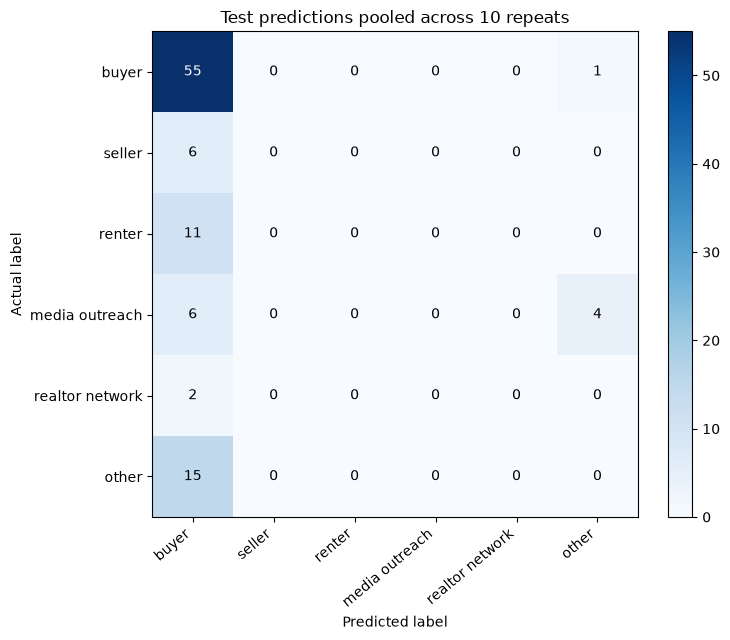

Held-out predictions for every repeat:


,repeat,item_id,actual_label,predicted_label,correct
0,1,V22,other,buyer,False
1,1,V27,media outreach,buyer,False
2,1,V19,buyer,buyer,True
3,1,V30,buyer,buyer,True
4,1,V21,media outreach,buyer,False
...,...,...,...,...,...
95,10,V29,buyer,buyer,True
96,10,V10,buyer,buyer,True
97,10,V1,seller,buyer,False
98,10,V6,other,buyer,False


Saved metrics, predictions, and the confusion matrix to outputs.


In [5]:
def format_metrics(frame, metric_columns):
    formatted = frame.copy()
    for column in metric_columns:
        formatted[column] = formatted[column].map(
            lambda value: "N/A" if pd.isna(value) else f"{float(value):.3f}"
        )
    return formatted


output_dir = data_path.parent / "outputs"
output_dir.mkdir(exist_ok=True)

class_metrics.to_csv(output_dir / "class_metrics_by_repeat.csv", index=False)
class_summary.to_csv(output_dir / "class_metrics_summary.csv", index=False)
repeat_summary.to_csv(output_dir / "repeat_summary.csv", index=False)
predictions.to_csv(output_dir / "test_predictions.csv", index=False)
confusion_by_repeat.to_csv(output_dir / "confusion_matrix_by_repeat.csv", index=False)

summed_frame = pd.DataFrame(summed_confusion, index=CLASS_NAMES, columns=CLASS_NAMES)
summed_frame.index.name = "actual_label"
summed_frame.to_csv(output_dir / "confusion_matrix_sum.csv")

# Rebuild the split lists for the settings file. The seeds match score_repeat.
split_records = []
for repeat_index in range(N_REPEATS):
    split_seed = RANDOM_SEED + repeat_index
    train_positions, test_positions = train_test_positions(len(dataset), TRAIN_SIZE, split_seed)
    split_records.append({
        "repeat": repeat_index + 1,
        "split_seed": split_seed,
        "train_item_ids": [str(item_ids[position]) for position in train_positions],
        "test_item_ids": [str(item_ids[position]) for position in test_positions],
    })

run_settings = {
    "data_path": str(data_path),
    "label_column": LABEL_COLUMN,
    "class_names": CLASS_NAMES,
    "train_size": TRAIN_SIZE,
    "test_size": int(test_size),
    "n_repeats": N_REPEATS,
    "random_seed": RANDOM_SEED,
    "split_rule": "Repeat k (starting at 1) uses numpy RandomState(RANDOM_SEED + k - 1). The first TRAIN_SIZE positions of the permutation are training rows.",
    "vectorizer": {"lowercase": True, "ngram_range": [1, 1], "min_df": 1, "stop_words": None},
    "classifier": {
        "type": "LogisticRegression",
        "C": 1.0,
        "penalty": "l2",
        "class_weight": "balanced",
        "solver": "lbfgs",
        "max_iter": 1000,
        "random_state": RANDOM_SEED,
    },
    "sklearn_version": sklearn.__version__,
    "numpy_version": np.__version__,
    "splits": split_records,
}
(output_dir / "run_settings.json").write_text(json.dumps(run_settings, indent=2))

repeat_metric_columns = [
    "accuracy",
    "macro_precision",
    "macro_recall",
    "macro_f1",
    "macro_specificity",
    "macro_auc",
]
print("One row per repeat. Macro averages skip classes whose metric is N/A on that test set.")
display(format_metrics(repeat_summary, repeat_metric_columns))

summary_metric_columns = []
for metric_name in METRIC_NAMES:
    summary_metric_columns.append(metric_name + "_mean")
    summary_metric_columns.append(metric_name + "_std")
print("Mean and sample standard deviation across repeats. defined_runs counts repeats with a defined metric.")
display(format_metrics(class_summary, summary_metric_columns))

print("Summed confusion matrix. Rows are the actual label. Columns are the predicted label.")
display(summed_frame)

figure, axis = plt.subplots(figsize=(8.5, 6.5))
image = axis.imshow(summed_confusion, cmap="Blues")
axis.set_xticks(range(len(CLASS_NAMES)))
axis.set_yticks(range(len(CLASS_NAMES)))
axis.set_xticklabels(CLASS_NAMES, rotation=40, ha="right")
axis.set_yticklabels(CLASS_NAMES)
axis.set_xlabel("Predicted label")
axis.set_ylabel("Actual label")
axis.set_title(f"Test predictions pooled across {N_REPEATS} repeats")
dark_text_cutoff = summed_confusion.max() / 2 if summed_confusion.max() else 0
for row_index in range(summed_confusion.shape[0]):
    for column_index in range(summed_confusion.shape[1]):
        count = int(summed_confusion[row_index, column_index])
        text_color = "white" if count > dark_text_cutoff else "black"
        axis.text(column_index, row_index, str(count), ha="center", va="center", color=text_color)
figure.colorbar(image, ax=axis, fraction=0.046, pad=0.04)
figure.tight_layout()
figure.savefig(output_dir / "confusion_matrix_sum.png", dpi=150, bbox_inches="tight")
plt.show()

print("Held-out predictions for every repeat:")
display(predictions[["repeat", "item_id", "actual_label", "predicted_label", "correct"]])
print(f"Saved metrics, predictions, and the confusion matrix to {output_dir}.")


## How to read the baseline

Buyer accounts for 19 of the 30 messages. Seller and realtor network have one message each. Media outreach has two, and those two statements are an email request and an air-quality question. They do not share a stable wording pattern. Other still mixes greetings, a property-management question, a name-only line, and a move-in-area line.

Because the rare classes have one or two rows, many test sets will not contain them. Recall, F1, and AUC are then N/A. When the single example is held out, the model has never seen that class, so it cannot predict it. Precision is then N/A as well. Those gaps are a property of this 30-message file. The assignment does not ask for extra messages to fill them.

The 10 repeats reuse messages. The range of accuracy and macro F1 is the sensitivity of the score to which 10 messages are held out. It is not a confidence interval from 10 separate datasets.

Some statements can fit more than one intent. Examples already in this file are renting before buying, buying a home in order to rent it out, and asking about a specific house's rental rates. Those labels are kept as they stand in `expand_other`. Assignment 10 is the place to revisit the annotation rules.

The cell below states which classes scored highest and lowest on these 10 runs, and which confusions were most common.


In [6]:
def class_metric(class_summary_frame, class_name, column_name):
    matching = class_summary_frame.loc[class_summary_frame["class_name"] == class_name, column_name]
    if len(matching) == 0 or pd.isna(matching.iloc[0]):
        return None
    return float(matching.iloc[0])


def describe_results(class_summary_frame, class_metrics_frame, repeat_summary_frame, confusion_counts):
    lines = []
    accuracy_values = repeat_summary_frame["accuracy"]
    lines.append(
        f"Mean accuracy across {len(repeat_summary_frame)} repeats is {accuracy_values.mean():.3f} "
        f"(lowest {accuracy_values.min():.3f}, highest {accuracy_values.max():.3f})."
    )

    buyer_index = CLASS_NAMES.index("buyer")
    buyer_total = int(confusion_counts[buyer_index].sum())
    buyer_correct = int(confusion_counts[buyer_index, buyer_index])
    non_buyer_total = int(confusion_counts.sum() - buyer_total)
    non_buyer_correct = int(np.trace(confusion_counts) - buyer_correct)
    called_buyer = int(confusion_counts[:, buyer_index].sum() - buyer_correct)
    lines.append(
        f"In the pooled test sets, {buyer_correct} of {buyer_total} buyer messages are correct, "
        f"and {non_buyer_correct} of {non_buyer_total} non-buyer messages are correct. "
        f"{called_buyer} non-buyer messages are predicted as buyer."
    )

    positive_recall = class_summary_frame.loc[
        class_summary_frame["recall_mean"].fillna(0) > 0, "class_name"
    ].tolist()
    if positive_recall == ["buyer"]:
        lines.append("Buyer is the only class with mean recall above 0.")
    elif len(positive_recall) == 0:
        lines.append("No class has mean recall above 0.")
    else:
        lines.append("Classes with mean recall above 0: " + ", ".join(positive_recall) + ".")

    buyer_recall = class_metric(class_summary_frame, "buyer", "recall_mean")
    buyer_precision = class_metric(class_summary_frame, "buyer", "precision_mean")
    buyer_specificity = class_metric(class_summary_frame, "buyer", "specificity_mean")
    if buyer_recall is not None and buyer_precision is not None and buyer_specificity is not None:
        lines.append(
            f"Mean buyer recall is {buyer_recall:.3f}, mean buyer precision is {buyer_precision:.3f}, "
            f"and mean buyer specificity is {buyer_specificity:.3f}. "
            "The final label is usually buyer, including when the message belongs to another class."
        )

    macro_f1_values = repeat_summary_frame["macro_f1"].dropna()
    if len(macro_f1_values) > 0:
        lines.append(
            "Macro F1 averages only classes where precision and recall are both defined. "
            f"Those repeats count {repeat_summary_frame['f1_classes_counted'].mean():.1f} classes on average. "
            f"The mean of the macro F1 scores is {macro_f1_values.mean():.3f} "
            f"(lowest {macro_f1_values.min():.3f}, highest {macro_f1_values.max():.3f}). "
            "A class the model never predicts is N/A, so it does not lower this average."
        )

    renter_auc = class_metric(class_summary_frame, "renter", "auc_mean")
    renter_recall = class_metric(class_summary_frame, "renter", "recall_mean")
    if renter_auc is not None and renter_recall is not None:
        renter_line = (
            f"Mean renter recall is {renter_recall:.3f} and mean renter AUC is {renter_auc:.3f}."
        )
        if renter_recall == 0 and renter_auc > 0.5:
            renter_line += (
                " Renter never wins the final label, while its probability still ranks some renter "
                "messages above other messages. Buyer keeps the larger probability, so the predicted class stays buyer."
            )
        lines.append(renter_line)

    for class_name in CLASS_NAMES:
        held_out = class_metrics_frame.loc[
            (class_metrics_frame["class_name"] == class_name)
            & (class_metrics_frame["test_support"] > 0)
        ]
        if len(held_out) == 0:
            continue
        auc_values = held_out["auc"].dropna()
        unseen_when_tested = bool((held_out["train_support"] == 0).all())
        if unseen_when_tested and len(auc_values) > 0 and np.allclose(auc_values.to_numpy(), 0.5):
            lines.append(
                f"{class_name.capitalize()} is absent from training whenever it appears in a test set, "
                "so every test row gets probability 0 and the AUC is 0.5."
            )

    pairs = []
    for actual_index, actual_name in enumerate(CLASS_NAMES):
        for predicted_index, predicted_name in enumerate(CLASS_NAMES):
            if actual_index == predicted_index:
                continue
            count = int(confusion_counts[actual_index, predicted_index])
            if count > 0:
                pairs.append((count, actual_name, predicted_name))
    pairs.sort(reverse=True)
    if pairs:
        pair_text = "; ".join(
            f"{actual_name} predicted as {predicted_name} ({count} times)"
            for count, actual_name, predicted_name in pairs[:3]
        )
        lines.append("Most common confusions in the pooled test sets: " + pair_text + ".")

    lines.append(
        "Buyer has 19 messages and repeated words such as buy, home, and looking. "
        "The other classes have one to four messages, and several of those messages also use housing words, so the buyer weights fire on them too."
    )
    lines.append(
        "Renter shares wording with buyer. Some buyer messages are about a short-term rental or an Airbnb, and one renter message says rent before buying."
    )
    lines.append(
        "Media outreach is an email request plus an air-quality question. Those two statements do not share a request, so a weight learned from one does not identify the other. Other is still a mix of greetings, a property-management question, a name-only line, and a move-in-area line."
    )
    return "\n".join(lines)


print(describe_results(class_summary, class_metrics, repeat_summary, summed_confusion))


Mean accuracy across 10 repeats is 0.550 (lowest 0.400, highest 0.800).
In the pooled test sets, 55 of 56 buyer messages are correct, and 0 of 44 non-buyer messages are correct. 40 non-buyer messages are predicted as buyer.
Buyer is the only class with mean recall above 0.
Mean buyer recall is 0.983, mean buyer precision is 0.579, and mean buyer specificity is 0.090. The final label is usually buyer, including when the message belongs to another class.
Macro F1 averages only classes where precision and recall are both defined. Those repeats count 1.4 classes on average. The mean of the macro F1 scores is 0.579 (lowest 0.308, highest 0.889). A class the model never predicts is N/A, so it does not lower this average.
Mean renter recall is 0.000 and mean renter AUC is 0.749. Renter never wins the final label, while its probability still ranks some renter messages above other messages. Buyer keeps the larger probability, so the predicted class stays buyer.
Seller is absent from training wh